Patho - respi - deep learning simple

probleme de regression - pas d'activation sur la couche de sortie
peut tourner en local sur GPU ou aller sur google collab

essai de faire avec API sequentielle et API fonctionelle

paritr sur model B

In [1]:
# import packages 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots


In [2]:
#Chargement de fichier commun

# fichier fusionné par le groupe 
df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={'code_dept': str})

display(df.info())

df.columns.tolist()

cible = 'TousAge_allergie_urgences'
df[cible].describe()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

None

count    19968.000000
mean       744.778217
std        315.852165
min          0.000000
25%        538.838945
50%        699.809373
75%        900.156926
max       3636.363636
Name: TousAge_allergie_urgences, dtype: float64

In [3]:
# suppression des colonnes autre cible que taux_urgence_allergie_tous_age,  les categories Ntop et Npop

colonnes_supprimer = ["65plus_allergie_urgences", "0_14_allergie_urgences" , "15_64_allergie_urgences",
                         "0_14_asthme_urgences","15_64_asthme_urgences",  "TousAge_asthme_urgences", "65plus_asthme_urgences",
                         "0an_bronchiolite_urgences","TousAge_allergie_hospitalisation", "65plus_allergie_hospitalisation",
                         "0_14_allergie_hospitalisation", "15_64_allergie_hospitalisation", "0_14_asthme_hospitalisation", 
                         "15_64_asthme_hospitalisation", "TousAge_asthme_hospitalisation", "65plus_asthme_hospitalisation", 
                         "0an_bronchiolite_hospitalisation", "nom_dep","Ntop_Maladie_Respi_Chronique_tsage_9", 'Npop_Maladie_Respi_Chronique_tsage_9', 
                         'Ntop_Maladie_Respi_Chronique_0-14_9', 'Ntop_Maladie_Respi_Chronique_15-64_9',
                         'Ntop_Maladie_Respi_Chronique_65+_9', 'Npop_Maladie_Respi_Chronique_0-14_9', 'Npop_Maladie_Respi_Chronique_15-64_9',
                         'Npop_Maladie_Respi_Chronique_65+_9', "prev_calc_Maladie_Respi_Chronique_0-14_9" , 
                         "prev_calc_Maladie_Respi_Chronique_15-64_9", "prev_calc_Maladie_Respi_Chronique_65+_9"]

df_work = df.drop(columns = colonnes_supprimer).copy()

df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 52 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

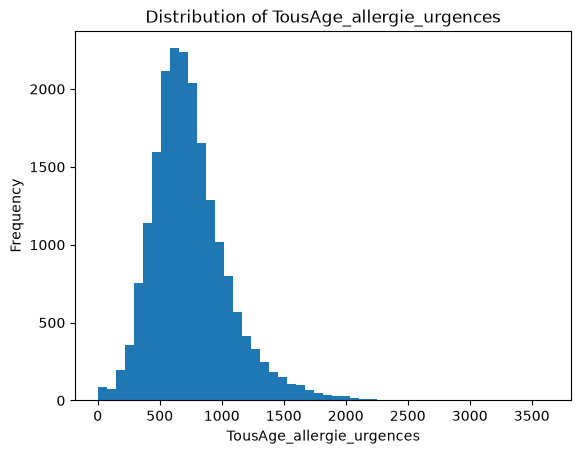

In [4]:
# print distribution of target variable
import matplotlib.pyplot as plt
plt.hist(df["TousAge_allergie_urgences"], bins=50)
plt.xlabel('TousAge_allergie_urgences')
plt.ylabel('Frequency')
plt.title('Distribution of TousAge_allergie_urgences')
plt.show()

La cible ne represente pas des valeurs extremes

In [5]:
import tensorflow as tf
print(tf.__version__)

2.21.0


# A: pretraitement
1. Encodage cyclique des semaines
2. creation de variable "taux_suivant"
3. Split du dataset - comme dans l'autre notebook


Encodage de la variable catégorielle - encodage avec encodeeur de Keras

Standardisation des variables numériques

Standardisation de la variable cible !!!!

## 1. Encodage cyclique des semaines

In [6]:

# extraire l'année et semaine,
df_work["annee"] = df_work["date_semaine"].str[:4].astype(int)
df_work["semaine"] = df_work["date_semaine"].str[-2:].astype(int)

# Représenter la saisonnalité annuelle par un cycle de 52 semaines

df_work["semaine_sin"] = np.sin(2*np.pi*df_work["semaine"]/52)
df_work["semaine_cos"] = np.cos(2*np.pi*df_work["semaine"]/52)

#trier par année, semaine et departement
df_work = df_work.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)
assert not df_work.duplicated(["code_dept", "annee", "semaine"]).any()                      #verifier si il y a des doublons

## 2. Création de la variable cible : taux_suivant

In [7]:
#creation des nouvelles colonnes pour les dates cibles et taux suivante 

df_work["taux_suivant"] = df_work.groupby("code_dept")[cible].shift(-1)       #regroupe les observations par departement et recupere la valeur de la ligne suivante dans la meme departement
df_work["taux_connu"] = df_work[cible]

# On rapproche aussi le libellé et le calendrier de la semaine à prévoir.
df_work["semaine_a_prevoir"] = df_work.groupby("code_dept")["date_semaine"].shift(-1)
df_work["annee_cible"] = df_work.groupby("code_dept")["annee"].shift(-1)
df_work["semaine_cible"] = df_work.groupby("code_dept")["semaine"].shift(-1)
df_work["semaine_cible_sin"] = df_work.groupby("code_dept")["semaine_sin"].shift(-1)
df_work["semaine_cible_cos"] = df_work.groupby("code_dept")["semaine_cos"].shift(-1)

In [8]:
df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 63 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [9]:
# La dernière semaine n’a pas de réponse suivante : on retire cette ligne, sans remplacer la cible par zéro.
data = df_work.dropna(subset=["taux_suivant", "taux_connu"]).copy()

data["annee_cible"] = data["annee_cible"].astype(int)
data["semaine_cible"] = data["semaine_cible"].astype(int)
data["semaine_cible_sin"] = data["semaine_cible_sin"].astype(float)
data["semaine_cible_cos"] = data["semaine_cible_cos"].astype(float)

data[["code_dept", "date_semaine", "semaine_a_prevoir", "taux_connu", "taux_suivant"]].head()


,code_dept,date_semaine,semaine_a_prevoir,taux_connu,taux_suivant
0,01,2021-S01,2021-S02,446.144041,254.939452
1,01,2021-S02,2021-S03,254.939452,361.228176
2,01,2021-S03,2021-S04,361.228176,531.600709
3,01,2021-S04,2021-S05,531.600709,289.184500
4,01,2021-S05,2021-S06,289.184500,637.348630


In [10]:
data.info()

<class 'pandas.DataFrame'>
Index: 19872 entries, 0 to 19966
Data columns (total 63 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19872 non-null  str    
 1   code_dept                                   19872 non-null  str    
 2   As in PM10                                  19872 non-null  float64
 3   BaP in PM10                                 19872 non-null  float64
 4   Cd in PM10                                  19872 non-null  float64
 5   Ni in PM10                                  19872 non-null  float64
 6   Pb in PM10                                  19872 non-null  float64
 7   NO2                                         19872 non-null  float64
 8   O3                                          19872 non-null  float64
 9   PM10                                        19872 non-null  float64
 10  PM2.5                     

In [11]:
# inventaire des colonnes sur data


# Colonnes numériques
cols_num = data.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = data.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 59 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'annee', 'semaine'

C:\Users\monik\AppData\Local\Temp\ipykernel_29936\3724286207.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()


## 3. Train - valid -test split

In [12]:

#separation train - valid - test
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")



Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


In [13]:
#split X et y

#colonnes à exclure: date_semaine, semaine_a_prevoir, TousAge_allergie_urgences, "semaine_cos", "semaine_sin",
# (semaine_cos, semaine_sin sont supprimées pour eviter la multicolinéarité)
exclure_X = [
    "taux_suivant",
    "date_semaine",
    "semaine_a_prevoir",
    "TousAge_allergie_urgences",
   "semaine_cos", "semaine_sin"
]

#Separation X, y 
X_train = train.drop(columns=exclure_X)
X_valid = valid.drop(columns=exclure_X)
X_test = test.drop(columns=exclure_X)


y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]

In [14]:
print(X_train.shape, X_valid.shape, X_test.shape)

(9888, 57) (4992, 57) (4992, 57)


## 3. Encodage

In [15]:
from sklearn.preprocessing import OneHotEncoder

# Initialiser l'encodeur
enc = OneHotEncoder(drop="first", handle_unknown="ignore",
                    sparse_output=False).set_output(transform="pandas")

# Encoder les départements
X_train_enc = enc.fit_transform(X_train[["code_dept"]])
X_valid_enc = enc.transform(X_valid[["code_dept"]])
X_test_enc = enc.transform(X_test[["code_dept"]])

# Ajouter les périodes déjà encodées et enlever code_dept
X_train = pd.concat([X_train.drop(columns = "code_dept"), X_train_enc], axis=1)
X_valid = pd.concat([X_valid.drop(columns = "code_dept"), X_valid_enc], axis=1)
X_test = pd.concat([X_test.drop(columns = "code_dept"), X_test_enc], axis=1)

In [16]:
print(X_train.shape, X_valid.shape, X_test.shape)

(9888, 151) (4992, 151) (4992, 151)


## 4. Standardisation

In [17]:
# Toutes les variables numériques à standardiser

# Sélectionner les variables numériques
numeriques = X_train.select_dtypes(include="number").columns

# Colonnes à exclure explicitement
exclure = [
    "annee", "semaine", "annee_cible", "semaine_cible", 
    "TousAge_allergie_urgences", "tp_tempete_poussiere_chasse_neige"
]

# Ajouter les colonnes binaires (0/1) 
exclure += [
    col for col in numeriques
    if X_train[col].dropna().isin([0, 1]).all()
]

# Conserver les variables à standardiser
variables_scaler = [col for col in numeriques if col not in exclure]

print("Colonnes à standardiser :", variables_scaler)
print("Nombre de colonnes à standardiser :", len(variables_scaler))
print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())

print("Colonnes exclues :", exclure)

Colonnes à standardiser : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'taux_connu', 'semaine_cible_sin', 'semaine_cible_cos']
Nombre de colonnes

In [18]:
from sklearn.preprocessing import StandardScaler

#instanciation de Scaler
X_scaler = StandardScaler().set_output(transform="pandas")

# Entrainer sur X_train variables_scaler (variables selectionné à standardiser)
X_scaler.fit(X_train[variables_scaler])

# Copier les DataFrames pour conserver les autres variables
X_train_scaled = X_train.copy()
X_valid_scaled = X_valid.copy()
X_test_scaled = X_test.copy()

# Standardiser uniquement les colonnes sélectionnées
X_train_scaled[variables_scaler] = X_scaler.transform(X_train[variables_scaler])
X_valid_scaled[variables_scaler] = X_scaler.transform(X_valid[variables_scaler])
X_test_scaled[variables_scaler] = X_scaler.transform(X_test[variables_scaler])


# Scaler pour la variable cible
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(np.asarray(y_train).reshape(-1, 1))
y_valid_scaled = y_scaler.transform(np.asarray(y_valid).reshape(-1, 1))
y_test_scaled = y_scaler.transform(np.asarray(y_test).reshape(-1, 1))

display(X_train_scaled.head())
y_train_scaled


,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,PM2.5,SO2,...,code_dept_86,code_dept_87,code_dept_88,code_dept_89,code_dept_90,code_dept_91,code_dept_92,code_dept_93,code_dept_94,code_dept_95
0,0.271351,1.371730,-0.352566,-0.213944,-0.337532,0.696637,-1.988649,0.682961,2.408096,1.442220,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.328297,2.788128,1.845559,0.825054,1.342580,1.621958,-1.633276,-0.182332,0.631188,3.728834,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.905721,0.708845,0.401077,1.907018,2.896368,0.443519,-0.308771,-1.092079,-0.451685,1.707615,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.740883,0.675182,0.652291,0.953952,1.797347,1.561214,-1.246794,-0.580346,-0.589611,3.342166,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.678945,0.597501,0.526684,0.103419,1.115197,1.431994,-1.452113,0.101964,-0.067250,5.029445,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


array([[-1.54165261],
       [-1.21224835],
       [-0.68423901],
       ...,
       [-0.13596129],
       [ 0.20909174],
       [ 0.27831353]], shape=(9888, 1))

In [19]:
with open("colonnes_X_train_B.txt", "r", encoding="utf-8") as f:
    colonnes_X_train_B = f.read().splitlines()

colonnes_X_train_scaled = X_train_scaled.columns.tolist()

In [20]:
# Colonnes présentes dans colonnes_X_train_B mais absentes de colonnes_X_train_scaled
uniquement_colonnes_X_train_B = sorted(set(colonnes_X_train_B) - set(colonnes_X_train_scaled))

# Colonnes présentes dans colonnes_X_train_scaled mais absentes de colonnes_X_train_B
uniquement_colonnes_X_train_scaled = sorted(set(colonnes_X_train_scaled) - set(colonnes_X_train_B))

# Colonnes communes
communes = sorted(set(colonnes_X_train_B) & set(colonnes_X_train_scaled))

print("Colonnes uniquement dans colonnes_X_train_B :", uniquement_colonnes_X_train_B)
print("Colonnes uniquement dans colonnes_X_train_scaled :", uniquement_colonnes_X_train_scaled)
print("Nombre de colonnes communes :", len(communes))

Colonnes uniquement dans colonnes_X_train_B : []
Colonnes uniquement dans colonnes_X_train_scaled : []
Nombre de colonnes communes : 151


In [21]:
X_train_scaled.describe()

,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,PM2.5,SO2,...,code_dept_86,code_dept_87,code_dept_88,code_dept_89,code_dept_90,code_dept_91,code_dept_92,code_dept_93,code_dept_94,code_dept_95
count,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,9.888000e+03,...,9888.000000,9888.000000,9888.000000,9888.000000,9888.000000,9888.000000,9888.000000,9888.000000,9888.000000,9888.000000
mean,-1.667131e-16,-5.173855e-17,-1.379695e-16,7.185910e-18,-2.299491e-17,-1.264720e-16,-7.473346e-16,-2.529440e-16,-1.609644e-16,5.748728e-17,...,0.010417,0.010417,0.010417,0.010417,0.010417,0.010417,0.010417,0.010417,0.010417,0.010417
std,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,1.000051e+00,...,0.101534,0.101534,0.101534,0.101534,0.101534,0.101534,0.101534,0.101534,0.101534,0.101534
min,-1.686696e+00,-5.237071e-01,-1.357423e+00,-3.750672e-01,-1.360759e+00,-1.781930e+00,-2.905445e+00,-1.922223e+00,-1.710017e+00,-1.192396e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-5.678119e-01,-4.621551e-01,-6.037801e-01,-2.239351e-01,-5.657731e-01,-7.131176e-01,-6.429167e-01,-6.972848e-01,-7.040613e-01,-4.573323e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-1.789934e-01,-3.683435e-01,-1.432207e-01,-1.521366e-01,-2.136707e-01,-2.069967e-01,3.249742e-02,-2.164475e-01,-2.756078e-01,-1.642103e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2.901074e-01,7.832707e-02,3.382732e-01,-5.002336e-02,3.271438e-01,5.015521e-01,6.856145e-01,4.772345e-01,4.228301e-01,1.887732e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2.075492e+01,2.978774e+01,2.677857e+01,5.224278e+01,2.531892e+01,5.801163e+00,3.511762e+00,8.426148e+00,5.863602e+00,2.696407e+01,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [22]:
X_train_scaled.abs().mean().sort_values(ascending=False).head(15)

annee_cible                             2021.504854
annee                                   2021.495146
semaine_cible                             26.747573
semaine                                   26.252427
semaine_cible_sin                          0.902103
semaine_cible_cos                          0.899049
densite_generalistes                       0.841585
temperature_kelvin                         0.839765
pct_artisans                               0.827829
visibilite                                 0.822500
pct_urbain                                 0.819604
pct_sans_activite                          0.816336
pct_retraites                              0.813422
humidite_relative                          0.812338
prev_Maladie_Respi_Chronique_tsage_9       0.809169
dtype: float64

In [23]:
print(X_train.shape, X_valid.shape, X_test.shape)

(9888, 151) (4992, 151) (4992, 151)


## Definition des fonctions

In [24]:
def plot_history(history):
    # Récupération des valeurs
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    mae = history.history['mae']
    val_mae = history.history['val_mae']

    epochs = range(1, len(loss) + 1)

    plt.figure(figsize=(10, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='Train Loss')
    plt.plot(epochs, val_loss, label='Val Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # MAE
    plt.subplot(1, 2, 2)
    plt.plot(epochs, mae, label='Train MAE')
    plt.plot(epochs, val_mae, label='Val MAE')
    plt.title('MAE over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('MAE')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [25]:
def plot_history_log(history):
    # Récupération des valeurs
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    mae = history.history['mae']
    val_mae = history.history['val_mae']

    epochs = range(1, len(loss) + 1)

#visualisation echelle logarithmique
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.yscale("log")
    plt.legend()
    plt.title("Loss over Epochs")

    plt.subplot(1, 2, 2)
    plt.plot(history.history["mae"], label="Train MAE")
    plt.plot(history.history["val_mae"], label="Val MAE")
    plt.yscale("log")
    plt.legend()
    plt.title("MAE over Epochs")

    plt.tight_layout()
    plt.show()

In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)
import pandas as pd

# Initialiser une seule fois
resultats = {}
predictions = {}

def prediction(model, nom_modele, dataset="valid"):

    # Sélection du dataset
    jeux = {
        "train": (X_train_scaled, y_train),
        "valid": (X_valid_scaled, y_valid),
        "test": (X_test_scaled, y_test),
        
    }

    X, y = jeux[dataset]

    # Prédiction et retour à l'échelle originale
    y_pred_scaled = model.predict(X).reshape(-1, 1)
    y_pred = y_scaler.inverse_transform(y_pred_scaled).ravel()

    predictions[(nom_modele, dataset)] = y_pred

    # Métriques
    mae = mean_absolute_error(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = root_mean_squared_error(y, y_pred)
    r2 = r2_score(y, y_pred)

    # Affichage
    print(f"{nom_modele} - {dataset}")
    print(f"MAE  : {mae:.2f}")
    print(f"MSE  : {mse:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R²   : {r2:.3f}")

    # Stockage des résultats
    resultats[(nom_modele, dataset)] = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    }

# B. Optimisation et régulation

On a 151 colonnes
2 puissance superieur: 2⁸ = 256
256 couches --> 128 --> 64 --> 32

definir:
nb de neuron 1er couche: 
- 2 puissance superieur de nb de colonnes (encodés et standardisés?)

- nb de couche: 32

- fonction d'activation des couches?
- fonction d'activation de sorite : rien

B: faire le couche avec API


a) 1er couche API sequentielle

C: compilation et entrainement

### 1. compilation et entrainement model sequentielle

1.a S - SGD

In [27]:
# sequentielle
from tensorflow.keras import Sequential, layers

# Reproductibilité
tf.keras.utils.set_random_seed(42)

modelS = Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear')
])

modelS.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,793 (38.25 KB)

 Trainable params: 9,793 (38.25 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
from tensorflow.keras.optimizers import SGD

modelS.compile(
   optimizer=SGD(learning_rate=1e-3),
   loss='mse',
   metrics=['mae']
)

#entrainement de modele
history = modelS.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    verbose=1       #0 = aucun texte, 1 = progress bar, 2 = une ligne par epoch.
)

Epoch 1/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2635399449018368.0000 - mae: 4259813.0000 - val_loss: 952158650368.0000 - val_mae: 975786.2500
Epoch 2/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 547357163520.0000 - mae: 728385.0625 - val_loss: 276301611008.0000 - val_mae: 525643.8750
Epoch 3/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 158834540544.0000 - mae: 392372.1562 - val_loss: 80178511872.0000 - val_mae: 283158.0938
Epoch 4/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 46091317248.0000 - mae: 211365.9844 - val_loss: 23266543616.0000 - val_mae: 152533.8125
Epoch 5/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 13374983168.0000 - mae: 113860.3125 - val_loss: 6751602176.0000 - val_mae: 82168.1562
Epoch 6/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 3881219584.0000 - mae: 61335.2227 - val_loss: 1959211264.0000 - val_mae: 44262.9805
Epoch 7/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1126269952.0000 - mae: 33040.5391 - val_loss: 56

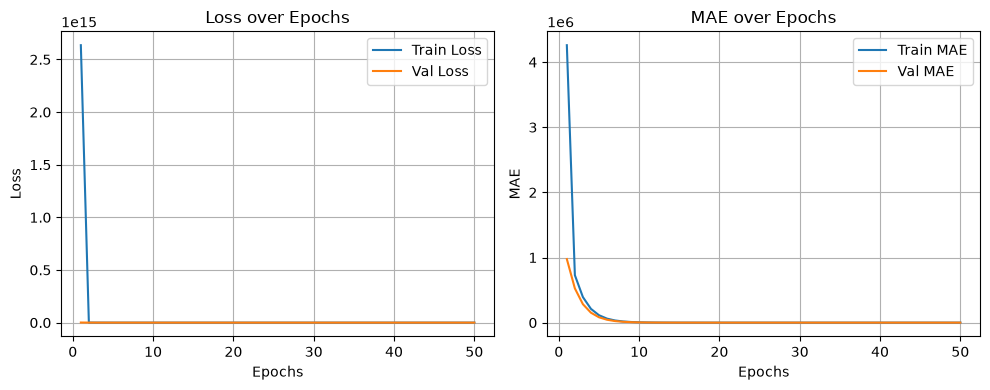

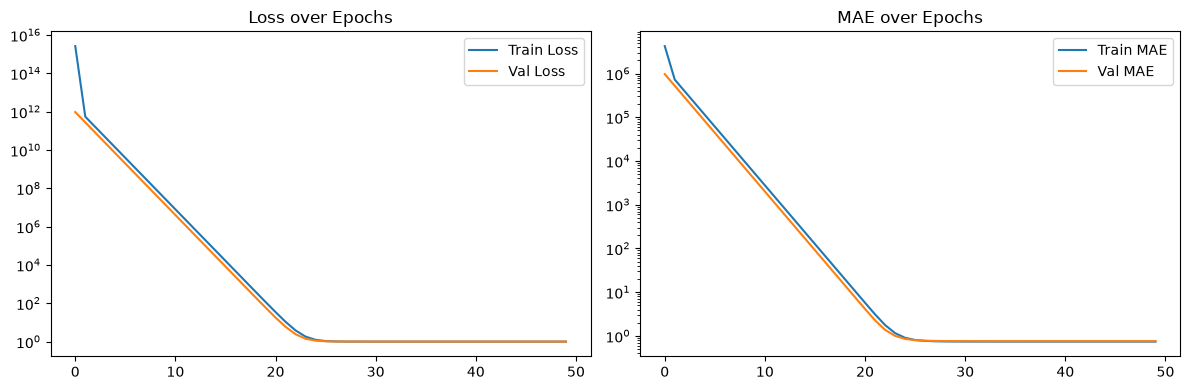

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
S - train
MAE  : 238.78
MSE  : 104116.50
RMSE : 322.67
R²   : -0.000
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
S - valid
MAE  : 244.73
MSE  : 104589.24
RMSE : 323.40
R²   : -0.000


In [29]:

plot_history(history)
plot_history_log(history)
prediction(modelS, "S", "train")
prediction(modelS, "S", "valid")

#1.b - Model S / Adam

In [30]:
# sequentielle
from tensorflow.keras import Sequential, layers

# Reproductibilité
tf.keras.utils.set_random_seed(42)

modelSA = Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear')
])

modelSA.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │         9,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,793 (38.25 KB)

 Trainable params: 9,793 (38.25 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
from tensorflow.keras.optimizers import Adam


modelSA.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

#entrainement de modele
historySA = modelSA.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    verbose=1       #0 = aucun texte, 1 = progress bar, 2 = une ligne par epoch.
)

Epoch 1/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1198.1006 - mae: 10.3519 - val_loss: 1.2660 - val_mae: 0.8732
Epoch 2/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9364 - mae: 0.7286 - val_loss: 0.9156 - val_mae: 0.7214
Epoch 3/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7769 - mae: 0.6543 - val_loss: 0.7898 - val_mae: 0.6599
Epoch 4/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7231 - mae: 0.6279 - val_loss: 0.7314 - val_mae: 0.6299
Epoch 5/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6979 - mae: 0.6141 - val_loss: 0.6868 - val_mae: 0.6082
Epoch 6/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6831 - mae: 0.6064 - val_loss: 0.6586 - val_mae: 0.5947
Epoch 7/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6655 - mae: 0.5990 - val_loss: 0.6355 - val_mae: 0.5872
Epoch 8/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6573 - mae: 0.5964 - val_loss: 0.7086 - val_mae: 0.6477
Epoch 9/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step 

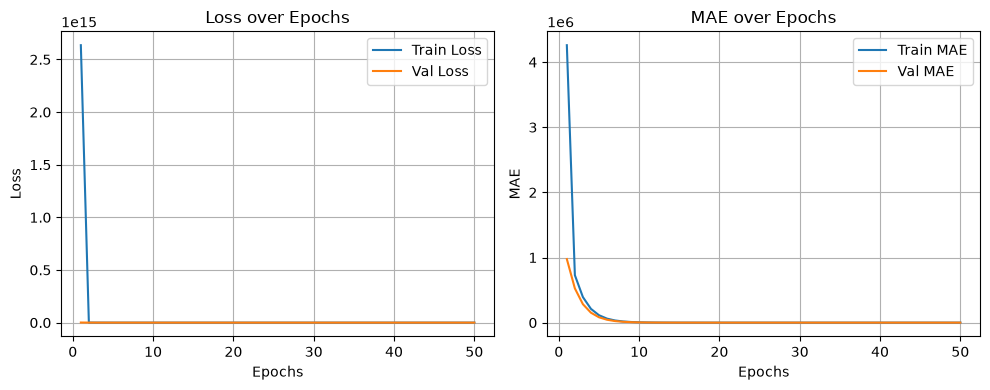

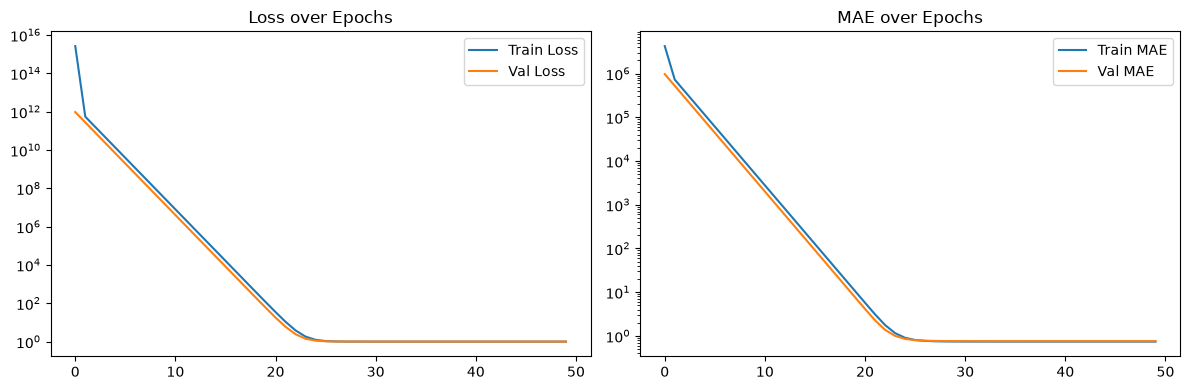

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
SA - train
MAE  : 197.93
MSE  : 68186.79
RMSE : 261.13
R²   : 0.345
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
SA - valid
MAE  : 189.51
MSE  : 63357.42
RMSE : 251.71
R²   : 0.394


In [32]:
plot_history(history)
plot_history_log(history)
prediction(modelSA, "SA", "train")
prediction(modelSA, "SA", "valid")

#1.c - Model S / Adam + early stopping

In [33]:
# sequentielle
from tensorflow.keras import Sequential, layers

# Reproductibilité
tf.keras.utils.set_random_seed(42)

modelSAe = Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear')
])

modelSAe.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         9,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,793 (38.25 KB)

 Trainable params: 9,793 (38.25 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
#Early stopping
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

modelSAe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

#entrainement de modele
historySAe = modelSAe.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    callbacks=[early_stop],  
    verbose=1       #0 = aucun texte, 1 = progress bar, 2 = une ligne par epoch.
)

Epoch 1/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1198.1006 - mae: 10.3519 - val_loss: 1.2660 - val_mae: 0.8732
Epoch 2/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9364 - mae: 0.7286 - val_loss: 0.9156 - val_mae: 0.7214
Epoch 3/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7769 - mae: 0.6543 - val_loss: 0.7898 - val_mae: 0.6599
Epoch 4/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7231 - mae: 0.6279 - val_loss: 0.7314 - val_mae: 0.6299
Epoch 5/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6979 - mae: 0.6141 - val_loss: 0.6868 - val_mae: 0.6082
Epoch 6/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6831 - mae: 0.6064 - val_loss: 0.6586 - val_mae: 0.5947
Epoch 7/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6655 - mae: 0.5990 - val_loss: 0.6355 - val_mae: 0.5872
Epoch 8/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6573 - mae: 0.5964 - val_loss: 0.7086 - val_mae: 0.6477
Epoch 9/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step 

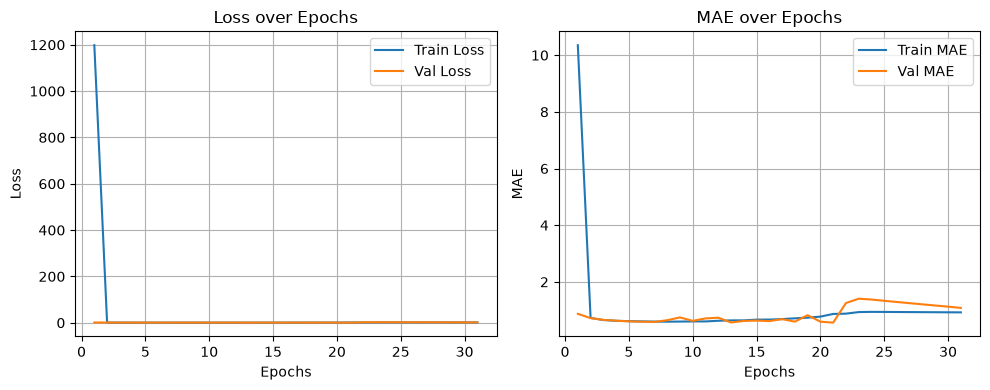

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
SAe - train
MAE  : 184.15
MSE  : 62383.16
RMSE : 249.77
R²   : 0.401
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
SAe - valid
MAE  : 181.55
MSE  : 60174.14
RMSE : 245.30
R²   : 0.425


In [35]:
plot_history(historySAe)
prediction(modelSAe, "SAe", "train")
prediction(modelSAe, "SAe", "valid")

1.d S / Adam / ReduceOnPlateau

In [36]:
# sequentielle
from tensorflow.keras import Sequential, layers

# Reproductibilité
tf.keras.utils.set_random_seed(42)

modelSAr = Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear')
])
modelSAr.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         9,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,793 (38.25 KB)

 Trainable params: 9,793 (38.25 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# ReduceLROnPlateau


from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    verbose=1,
    min_lr=1e-6
)

modelSAr.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

#entrainement de modele
historySAr = modelSAr.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    callbacks=[lr_scheduler],  
    verbose=1       #0 = aucun texte, 1 = progress bar, 2 = une ligne par epoch.
)

Epoch 1/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1198.1006 - mae: 10.3519 - val_loss: 1.2660 - val_mae: 0.8732 - learning_rate: 0.0010
Epoch 2/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9364 - mae: 0.7286 - val_loss: 0.9156 - val_mae: 0.7214 - learning_rate: 0.0010
Epoch 3/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7769 - mae: 0.6543 - val_loss: 0.7898 - val_mae: 0.6599 - learning_rate: 0.0010
Epoch 4/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7231 - mae: 0.6279 - val_loss: 0.7314 - val_mae: 0.6299 - learning_rate: 0.0010
Epoch 5/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6979 - mae: 0.6141 - val_loss: 0.6868 - val_mae: 0.6082 - learning_rate: 0.0010
Epoch 6/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6831 - mae: 0.6064 - val_loss: 0.6586 - val_mae: 0.5947 - learning_rate: 0.0010
Epoch 7/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6655 - mae: 0.5990 - val_loss: 0.6355 - val_mae: 0.5872 - learning_rate: 0.0010
Ep

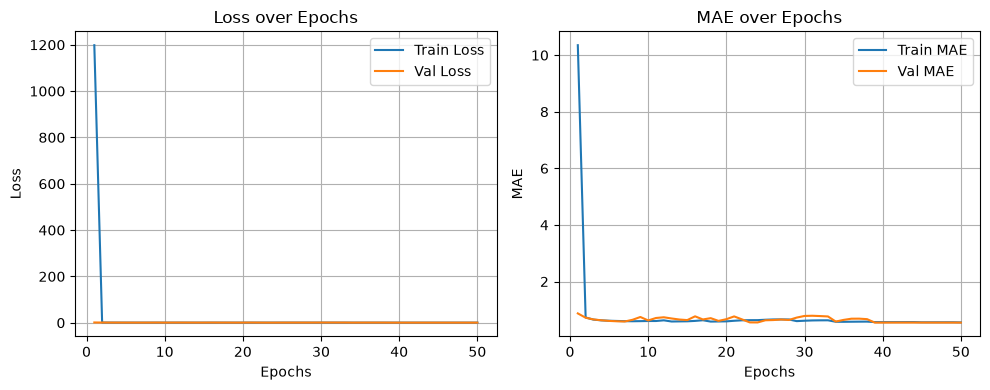

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
SAr - train
MAE  : 177.02
MSE  : 59283.12
RMSE : 243.48
R²   : 0.431
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
SAr - valid
MAE  : 176.85
MSE  : 58235.36
RMSE : 241.32
R²   : 0.443


In [38]:
plot_history(historySAr)
prediction(modelSAr, "SAr", "train")
prediction(modelSAr, "SAr", "valid")

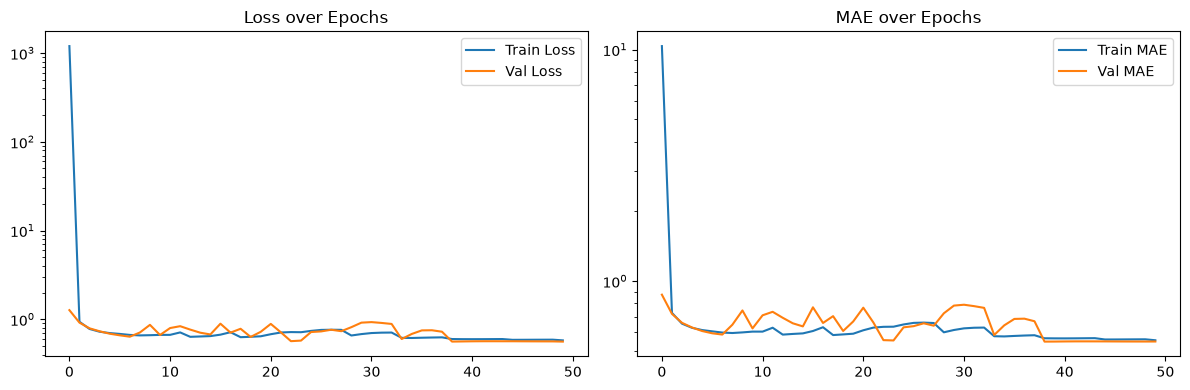

In [39]:
plot_history_log(historySAr)

### 2. compilation et entrainement model fonctionelle
descent de gradients: ADAM



2.a pas de callback

In [40]:
from tensorflow.keras import Model, layers, Input

# Reproductibilité
tf.keras.utils.set_random_seed(42)

inputs = Input(shape=(X_train_scaled.shape[1],))

x = layers.Dense(128, activation='relu')(inputs)    # apprend des représentations à partir des variables d'entrée.     
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

outputs = layers.Dense(1, activation='linear')(x)

model2a = Model(inputs=inputs, outputs=outputs)

model2a.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 151)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,337 (118.50 KB)

 Trainable params: 30,337 (118.50 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
from tensorflow.keras.optimizers import Adam


model2a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

#entrainement de modele
history2a = model2a.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    verbose=1       #0 = aucun texte, 1 = progress bar, 2 = une ligne par epoch.
)

Epoch 1/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 51.0624 - mae: 2.4906 - val_loss: 1.2400 - val_mae: 0.9379
Epoch 2/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8233 - mae: 0.6794 - val_loss: 0.6416 - val_mae: 0.6003
Epoch 3/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8450 - mae: 0.6976 - val_loss: 0.6154 - val_mae: 0.5824
Epoch 4/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8594 - mae: 0.7053 - val_loss: 0.7853 - val_mae: 0.7027
Epoch 5/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9954 - mae: 0.7755 - val_loss: 0.7340 - val_mae: 0.6729
Epoch 6/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.0439 - mae: 0.7868 - val_loss: 0.5896 - val_mae: 0.5588
Epoch 7/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.3124 - mae: 0.8827 - val_loss: 4.3193 - val_mae: 1.9579
Epoch 8/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.7516 - mae: 1.0474 - val_loss: 3.3843 - val_mae: 1.7096
Epoch 9/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - l

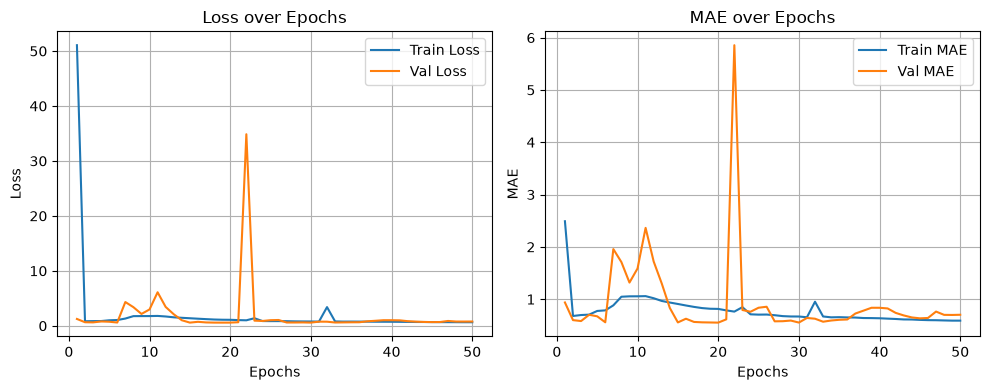

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
2a - train
MAE  : 227.34
MSE  : 81689.39
RMSE : 285.81
R²   : 0.215
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
2a - valid
MAE  : 226.73
MSE  : 80395.78
RMSE : 283.54
R²   : 0.231


In [42]:
plot_history(history2a)
prediction(model2a, "2a", "train")
prediction(model2a, "2a", "valid")

2.B - Early stopping

In [43]:
from tensorflow.keras import Model, layers, Input

# Reproductibilité
tf.keras.utils.set_random_seed(42)

inputs = Input(shape=(X_train_scaled.shape[1],))

x = layers.Dense(128, activation='relu')(inputs)    # apprend des représentations à partir des variables d'entrée.     
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

outputs = layers.Dense(1, activation='linear')(x)

model2b = Model(inputs=inputs, outputs=outputs)

In [44]:
#Early stopping

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


model2b.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)


history2b = model2b.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 51.0624 - mae: 2.4906 - val_loss: 1.2400 - val_mae: 0.9379
Epoch 2/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8233 - mae: 0.6794 - val_loss: 0.6416 - val_mae: 0.6003
Epoch 3/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8450 - mae: 0.6976 - val_loss: 0.6154 - val_mae: 0.5824
Epoch 4/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8594 - mae: 0.7053 - val_loss: 0.7853 - val_mae: 0.7027
Epoch 5/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.9954 - mae: 0.7755 - val_loss: 0.7340 - val_mae: 0.6729
Epoch 6/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.0439 - mae: 0.7868 - val_loss: 0.5896 - val_mae: 0.5588
Epoch 7/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.3124 - mae: 0.8827 - val_loss: 4.3193 - val_mae: 1.9579
Epoch 8/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.7516 - mae: 1.0474 - val_loss: 3.3843 - val_mae: 1.7096
Epoch 9/50
309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - l

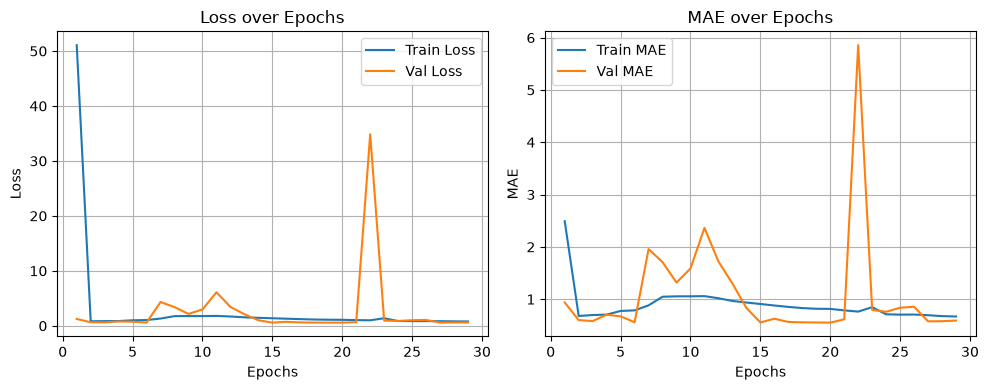

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
2b - train
MAE  : 179.30
MSE  : 60473.28
RMSE : 245.91
R²   : 0.419
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
2b - valid
MAE  : 179.18
MSE  : 59449.60
RMSE : 243.82
R²   : 0.432


In [45]:
plot_history(history2b)
prediction(model2b, "2b", "train")
prediction(model2b, "2b", "valid")

2.c ReduceLROnPlateau

In [46]:
from tensorflow.keras import Model, layers, Input

# Reproductibilité
tf.keras.utils.set_random_seed(42)

inputs = Input(shape=(X_train_scaled.shape[1],))

x = layers.Dense(128, activation='relu')(inputs)    # apprend des représentations à partir des variables d'entrée.     
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

outputs = layers.Dense(1, activation='linear')(x)

model2c = Model(inputs=inputs, outputs=outputs)


Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 24: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 29: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 34: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 39: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 48: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.


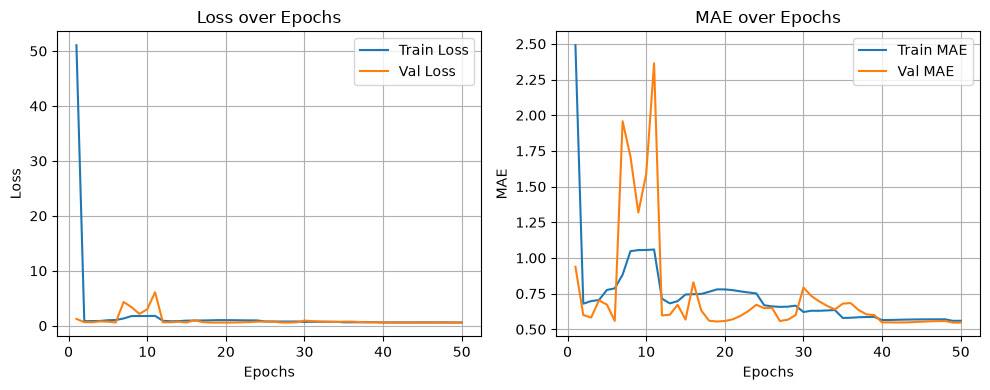

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
2c - train
MAE  : 176.19
MSE  : 59161.81
RMSE : 243.23
R²   : 0.432
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
2c - valid
MAE  : 176.41
MSE  : 58355.47
RMSE : 241.57
R²   : 0.442


In [47]:
# ReduceLROnPlateau


from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    verbose=1,
    min_lr=1e-6
)

model2c.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

history2c = model2c.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    batch_size=32,
    epochs=50,
    callbacks=[lr_scheduler],
    verbose=0
)

plot_history(history2c)
# Prédictions du réseau de neurones (standardisées)
prediction(model2c, "2c", "train")
prediction(model2c, "2c", "valid")


In [48]:
comparaison = pd.DataFrame.from_dict(
    resultats,
    orient="index"
)

comparaison.index = pd.MultiIndex.from_tuples(
    comparaison.index,
    names=["Modèle", "Dataset"]
)

display(comparaison.round(2))

MAE        MSE    RMSE    R²
Modèle Dataset                                 
S      train    238.78  104116.50  322.67 -0.00
       valid    244.73  104589.24  323.40 -0.00
SA     train    197.93   68186.79  261.13  0.35
       valid    189.51   63357.42  251.71  0.39
SAe    train    184.15   62383.16  249.77  0.40
       valid    181.55   60174.14  245.30  0.42
SAr    train    177.02   59283.12  243.48  0.43
       valid    176.85   58235.36  241.32  0.44
2a     train    227.34   81689.39  285.81  0.22
       valid    226.73   80395.78  283.54  0.23
2b     train    179.30   60473.28  245.91  0.42
       valid    179.18   59449.60  243.82  0.43
2c     train    176.19   59161.81  243.23  0.43
       valid    176.41   58355.47  241.57  0.44

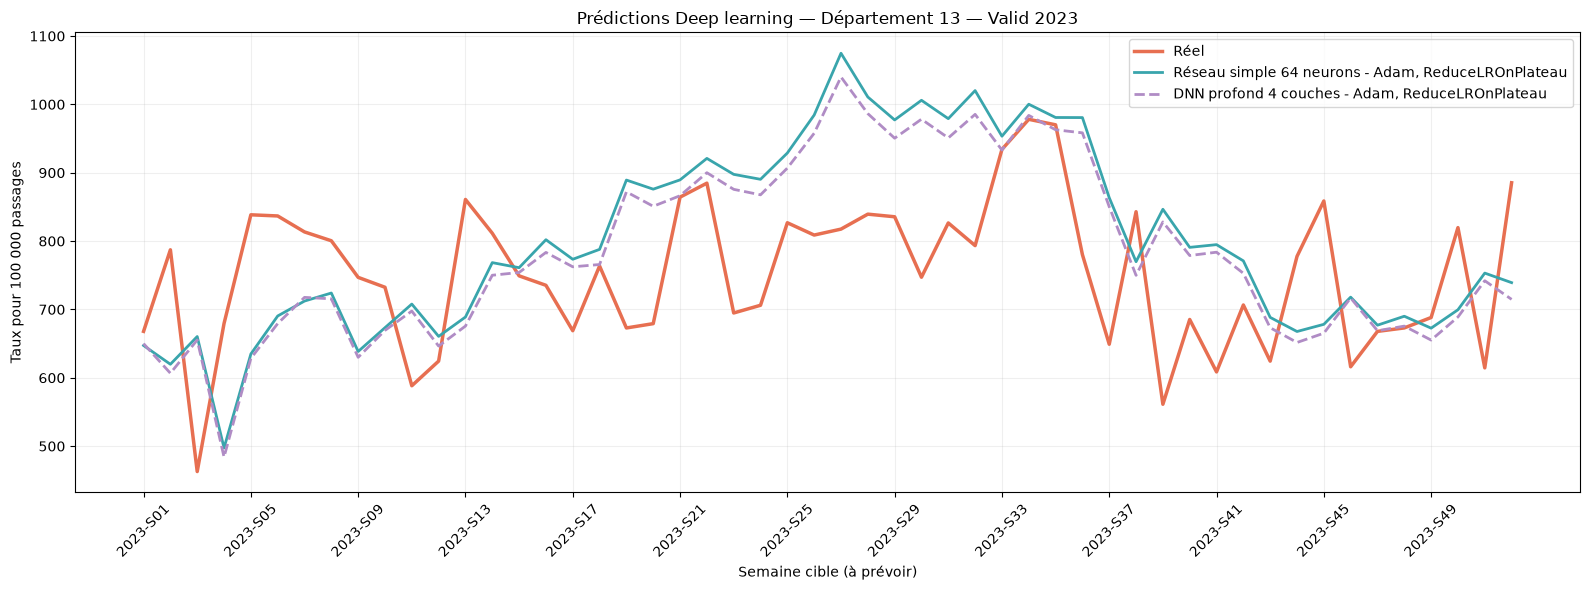

In [53]:
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Réel"] = np.asarray(y_valid).ravel()
comparaison["DNN SAr"] = predictions[("SAr", "valid")]
comparaison["DNN 2c"] = predictions[("2c", "valid")]


# Filtrer et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")


# Graphique
plt.figure(figsize=(16, 6))

plt.plot(courbes["semaine_a_prevoir"], courbes["Réel"],
         label="Réel", color="#E76F51", linewidth=2.5)

plt.plot(courbes["semaine_a_prevoir"], courbes["DNN SAr"],
         label="Réseau simple 64 neurons - Adam, ReduceLROnPlateau",
         color="#39A5AC", linewidth=2)

plt.plot(courbes["semaine_a_prevoir"], courbes["DNN 2c"],
         label="DNN profond 4 couches - Adam, ReduceLROnPlateau",
         color="#B08CC5", linewidth=2, linestyle="--")

# Mise en forme
plt.title(f"Prédictions Deep learning — Département {dept} — Valid 2023")
plt.ylabel("Taux pour 100 000 passages")
plt.xlabel("Semaine cible (à prévoir)")

plt.xticks(courbes["semaine_a_prevoir"].iloc[::4], rotation=45)
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

3. Sans standardisation et encodage 

In [50]:
from tensorflow.keras import Model, layers, Input

# Reproductibilité
tf.keras.utils.set_random_seed(42)

inputs = Input(shape=(X_train.shape[1],))

x = layers.Dense(128, activation='relu')(inputs)    # apprend des représentations à partir des variables d'entrée.     
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

outputs = layers.Dense(1, activation='linear')(x)

model3 = Model(inputs=inputs, outputs=outputs)


Epoch 14: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 22: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 34: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 40: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


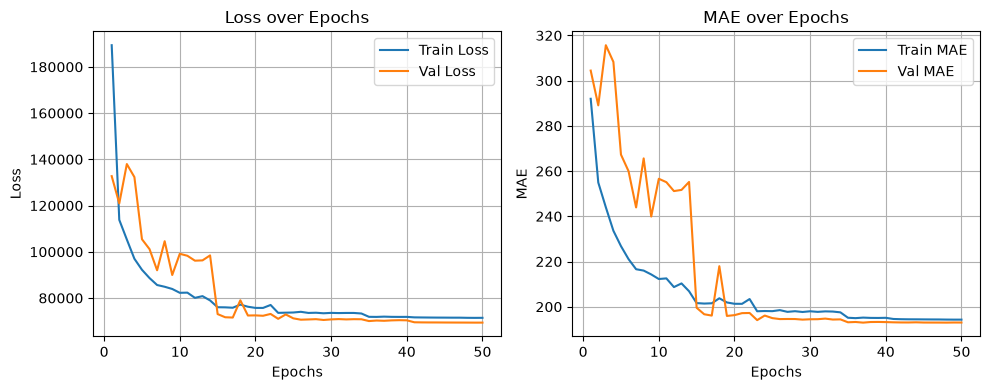

309/309 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
3 - train
MAE  : 12130.51
MSE  : 147486395.37
RMSE : 12144.40
R²   : -1415.563
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
3 - valid
MAE  : 12148.13
MSE  : 147908843.49
RMSE : 12161.78
R²   : -1413.242


In [51]:
# ReduceLROnPlateau


from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    verbose=1,
    min_lr=1e-6
)

model3.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

history3 = model3.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=32,
    epochs=50,
    callbacks=[lr_scheduler],
    verbose=0
)

plot_history(history3)
prediction(model3, "3", "train")
prediction(model3, "3", "valid")


In [52]:
comparaison = pd.DataFrame.from_dict(
    resultats,
    orient="index"
)

comparaison.index = pd.MultiIndex.from_tuples(
    comparaison.index,
    names=["Modèle", "Dataset"]
)

display(comparaison.round(2))

MAE           MSE      RMSE       R²
Modèle Dataset                                           
S      train      238.78  1.041165e+05    322.67    -0.00
       valid      244.73  1.045892e+05    323.40    -0.00
SA     train      197.93  6.818679e+04    261.13     0.35
       valid      189.51  6.335742e+04    251.71     0.39
SAe    train      184.15  6.238316e+04    249.77     0.40
       valid      181.55  6.017414e+04    245.30     0.42
SAr    train      177.02  5.928312e+04    243.48     0.43
       valid      176.85  5.823536e+04    241.32     0.44
2a     train      227.34  8.168939e+04    285.81     0.22
       valid      226.73  8.039578e+04    283.54     0.23
2b     train      179.30  6.047328e+04    245.91     0.42
       valid      179.18  5.944960e+04    243.82     0.43
2c     train      176.19  5.916181e+04    243.23     0.43
       valid      176.41  5.835547e+04    241.57     0.44
3      train    12130.51  1.474864e+08  12144.40 -1415.56
       valid    12148.13  1.479088e+08  12161.78 -1413.24